I plan to compare The Wonderful Wizard of Oz and The Marvelous Land of Oz both by L. Frank Baum. For different authors, I chose The Wonderful Wizard of Oz by L. Frank Baum and Alices adventures in Wonderland by Lewis Carroll. I chose these because they are easily accessible online and I am a fan of fantasy books. I would have preferred some newer books but none of my favorites are free online. The question i propose is this: how does the tone of The Wonderful Wizard of Oz and The Marvelous Land of Oz differ? These are both by the same artist and it will be interesting to compare how his writing changed between these books. Is one more dark than the other? More uplifting or focused on fantasy? I also plan to look at these themes outide of L. Frank Baum, comparing The Wonderful Wizard of Oz with another fantasy book from that time, Alices Adventures in Wonderland by Lewis Carroll. 

In [31]:
# This block will parse the books and seperate them into useful objects like word count, top words, and total count of different words

import requests, re, nltk
from bs4 import BeautifulSoup
from nltk import clean_html
from collections import Counter
import operator

# we may not care about the usage of stop words
stop_words = nltk.corpus.stopwords.words('english') + [
 'ut', '\'re','.', ',', '--', '\'s', '?', ')', '(', ':', '\'',
 '\"', '-', '}', '{', '&', '|', u'\u2014' ]

# We most likely would like to remove html markup
def cleanHtml (html):
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, 'html.parser')
    return soup .get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord (w):
    # r in r'[.,"\']' tells to treat \ as a regular character 
    # but we need to escape ' with \'
    # any character between the brackets [] is to be removed 
    wn = re.sub('[,"\.\'&\|:@>*;/=]', "", w)
    # get rid of numbers
    return re.sub('^[0-9\.]*$', "", wn)
       
# define a function to get text/clean/calculate frequency
def get_wf (URL):
    # first get the web page
    r = requests .get(URL)
    
    # Now clean
    # remove html markup
    t = cleanHtml (r .text) .lower()
    
    # split string into an array of words using any sequence of spaces "\s+" 
    wds = re .split('\s+',t)
    
    # remove periods, commas, etc stuck to the edges of words
    for i in range(len(wds)):
        wds [i] = cleanWord (wds [i])
    
    # If satisfied with results, lets go to the next step: calculate frequencies
    # We can write a loop to create a dictionary, but 
    # there is a special function for everything in python
    # in particular for counting frequencies (like function table() in R)
    wf = Counter (wds)
    
    # Remove stop words from the dictionary wf
    for k in stop_words:
        wf. pop(k, None)
        
    #how many regular words in the document?
    tw = 0
    for w in wf:
       tw += wf[w] 
        
    
    # Get ordered list
    wfs = sorted (wf .items(), key = operator.itemgetter(1), reverse=True)
    ml = min(len(wfs),15)

    #Reverse the list because barh plots items from the bottom
    # wf gives every word + count
    return (wf, wfs [ 0:ml ] [::-1], tw)
        
# Now populate two lists  
# Wonderful Wizard of Oz
(wwo_counts, wf_wwo, tw_wwo) = get_wf('https://www.gutenberg.org/files/55/55-h/55-h.htm')
# Marvelous land of Oz
(mlo_counts, wf_mlo, tw_mlo) = get_wf('https://www.gutenberg.org/files/54/54-h/54-h.htm')
# Alices Adventures in Wonderland
(aaw_counts, wf_aaw, tw_aaw) = get_wf('https://www.gutenberg.org/cache/epub/11/pg11-images.html')

In [32]:
# This block Prints some basic information about the books including word count and top words from each book

# Word count for each book
print("Word Count:")
print("Wonderful Wizard of Oz:", tw_wwo)
print("Marvelous Land of Oz:", tw_mlo)
print("Alice's Adventures in Wonderland:", tw_aaw)

# Top words for each book
print("Top Words:")
print("The Wonderful Wizard of Oz")
print(wf_wwo)

print("\nThe Marvelous Land of Oz")
print(wf_mlo)

print("\nAlice's Adventures in Wonderland")
print(wf_aaw)

Word Count:
Wonderful Wizard of Oz: 19588
Marvelous Land of Oz: 23943
Alice's Adventures in Wonderland: 15684
Top Words:
The Wonderful Wizard of Oz
[('would', 113), ('asked', 114), ('could', 118), ('one', 119), ('witch', 119), ('little', 139), ('tin', 139), ('great', 142), ('“i', 143), ('oz', 143), ('lion', 169), ('woodman', 175), ('scarecrow', 215), ('said', 331), ('dorothy', 340)]

The Marvelous Land of Oz
[('must', 94), ('woggle-bug', 99), ('boy', 102), ('mombi', 103), ('pumpkinhead', 110), ('saw-horse', 125), ('one', 127), ('woodman', 133), ('tin', 136), ('jack', 150), ('upon', 164), ('“i', 169), ('scarecrow', 271), ('tip', 282), ('said', 321)]

Alice's Adventures in Wonderland
[('queen', 64), ('see', 65), ('gutenberg', 66), ('thought', 73), ('would', 77), ('could', 77), ('like', 78), ('went', 83), ('project', 84), ('', 89), ('one', 90), ('“i', 121), ('little', 125), ('alice', 374), ('said', 456)]


In [33]:
# This block splits up each book into its word categories, measuring the frequency of dark/positive/fantasy type words per 1000 words

# For these lists i purposfully left out words that may be skewed to one book like: Wicked, Witch, Wonderful, Queen, etc.
# List of common dark wods
dark_words = [
    'death', 'dead', 'die', 'died',
    'kill', 'killed', 'killing',
    'fear', 'afraid', 'frightened', 'fright',
    'danger', 'dangerous',
    'evil', 'cruel', 'cruelty',
    'sad', 'sadness', 'sorrow',
    'hurt', 'horrible', 'terrible',
    'pain', 'suffer', 'suffering'
]

# List of common positive words
positive_words = [
    'happy', 'happiness',
    'joy', 'joyful',
    'glad',
    'love', 'loved',
    'laugh', 'laughed', 'laughing',
    'smile', 'smiled', 'smiling',
    'kind', 'kindness',
    'hope', 'hopeful',
    'pleased', 'delighted',
    'cheerful', 'comfort'
]

# List of common words related to fantasy
fantasy_words = [
    'magic', 'magical',
    'enchanted', 'enchantment',
    'spell', 'spells',
    'fairy', 'fairies',
    'monster', 'monsters',
    'creature', 'creatures',
    'giant', 'giants',
    'dragon', 'dragons',
    'mysterious',
    'strange', 'stranger',
    'wonderland'
]

# This function will count the number of dark/positive/fantasy words in each book
# input: list of words with counts, and the list of words to compare to (dark/positive/fantasy)
# output: total number of words in the book that fall into the given category (dark/positive/fantasy)
def category_count(counts, word_list):
    total = 0
    
    for word in word_list:
        total += counts[word]
        
    return total

# this function will normalize the number of categorical words in each book to per 1000
# This is useful because the books have different numbers of words, this will make sure each word count is comparable
def per_thousand(counts, word_list, total_words):
    count = category_count(counts, word_list)
    return (count / total_words) * 1000

# print the number of catergorical words per 1000 for The Wonderful Wizard of Oz
print("THE WONDERFUL WIZARD OF OZ")
print("Dark:", per_thousand(wwo_counts, dark_words, tw_wwo))
print("Positive:", per_thousand(wwo_counts, positive_words, tw_wwo))
print("Fantasy:", per_thousand(wwo_counts, fantasy_words, tw_wwo))

# print the number of catergorical words per 1000 for The Marvelous Land of Oz
print("\nTHE MARVELOUS LAND OF OZ")
print("Dark:", per_thousand(mlo_counts, dark_words, tw_mlo))
print("Positive:", per_thousand(mlo_counts, positive_words, tw_mlo))
print("Fantasy:", per_thousand(mlo_counts, fantasy_words, tw_mlo))

# print the number of catergorical words per 1000 for Alices Adventures in Wonderland
print("\nALICE'S ADVENTURES IN WONDERLAND")
print("Dark:", per_thousand(aaw_counts, dark_words, tw_aaw))
print("Positive:", per_thousand(aaw_counts, positive_words, tw_aaw))
print("Fantasy:", per_thousand(aaw_counts, fantasy_words, tw_aaw))

THE WONDERFUL WIZARD OF OZ
Dark: 8.729834592607718
Positive: 6.48356136410047
Fantasy: 2.756789871349806

THE MARVELOUS LAND OF OZ
Dark: 3.9259908950423923
Positive: 4.636010524996867
Fantasy: 3.215971265087917

ALICE'S ADVENTURES IN WONDERLAND
Dark: 2.422851313440449
Positive: 2.996684519255292
Fantasy: 1.7214996174445294


In [34]:
# This block creates a table to compare these values

import pandas as pd

tone_data = {
    'Book': [
        'Wonderful Wizard of Oz',
        'Marvelous Land of Oz',
        "Alice's Adventures in Wonderland"
    ],
    
    'Dark': [
        per_thousand(wwo_counts, dark_words, tw_wwo),
        per_thousand(mlo_counts, dark_words, tw_mlo),
        per_thousand(aaw_counts, dark_words, tw_aaw)
    ],
    
    'Positive': [
        per_thousand(wwo_counts, positive_words, tw_wwo),
        per_thousand(mlo_counts, positive_words, tw_mlo),
        per_thousand(aaw_counts, positive_words, tw_aaw)
    ],
    
    'Fantasy': [
        per_thousand(wwo_counts, fantasy_words, tw_wwo),
        per_thousand(mlo_counts, fantasy_words, tw_mlo),
        per_thousand(aaw_counts, fantasy_words, tw_aaw)
    ]
}

tone_df = pd.DataFrame(tone_data)

tone_df

,Book,Dark,Positive,Fantasy
0,Wonderful Wizard of Oz,8.729835,6.483561,2.756790
1,Marvelous Land of Oz,3.925991,4.636011,3.215971
2,Alice's Adventures in Wonderland,2.422851,2.996685,1.721500


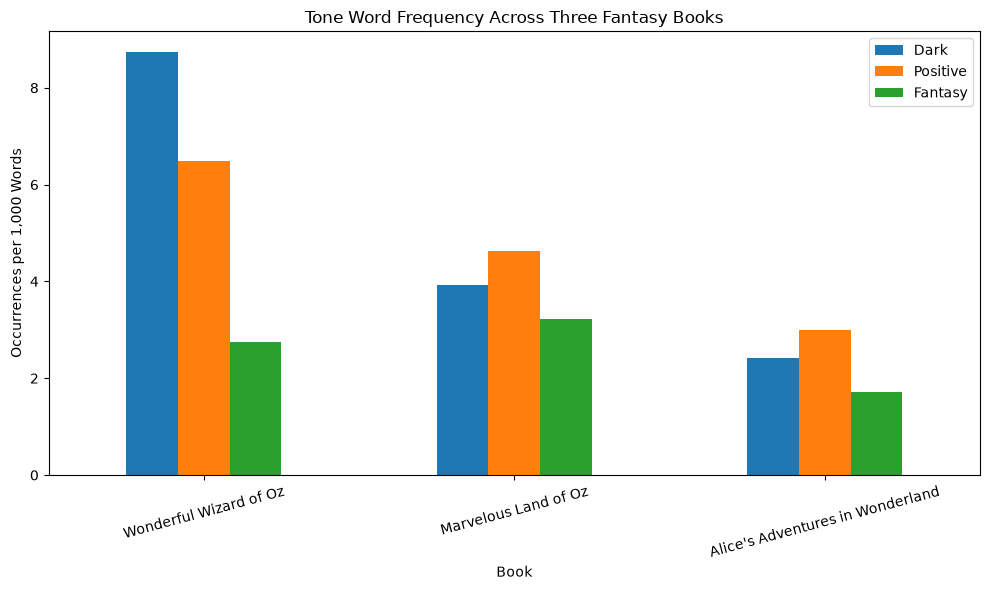

In [35]:
# This block plots the data above
import matplotlib.pyplot as plt

tone_df.set_index('Book').plot(kind='bar', figsize=(10,6))

plt.title('Tone Word Frequency Across Three Fantasy Books')
plt.ylabel('Occurrences per 1,000 Words')
plt.xlabel('Book')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [36]:
# This block will show the different words in each books category along with the count of those words
# This will ensure that no single word or words are skewing the data and the words that show up are meaningful
def show_category_words(counts, word_list):
    results = []
    
    for word in word_list:
        if counts[word] > 0:
            results.append((word, counts[word]))
    
    return sorted(results, key=lambda x: x[1], reverse=True)

print("WONDERFUL WIZARD - DARK")
print(show_category_words(wwo_counts, dark_words))

print("\nMARVELOUS LAND - DARK")
print(show_category_words(mlo_counts, dark_words))

print("\nALICE - DARK")
print(show_category_words(aaw_counts, dark_words))

print("WONDERFUL WIZARD - POSITIVE")
print(show_category_words(wwo_counts, positive_words))

print("\nMARVELOUS LAND - POSITIVE")
print(show_category_words(mlo_counts, positive_words))

print("\nALICE - POSITIVE")
print(show_category_words(aaw_counts, positive_words))

print("WONDERFUL WIZARD - FANTASY")
print(show_category_words(wwo_counts, fantasy_words))

print("\nMARVELOUS LAND - FANTASY")
print(show_category_words(mlo_counts, fantasy_words))

print("\nALICE - FANTASY")
print(show_category_words(aaw_counts, fantasy_words))

WONDERFUL WIZARD - DARK
[('afraid', 26), ('terrible', 24), ('hurt', 23), ('killed', 16), ('kill', 14), ('frightened', 13), ('dead', 11), ('fear', 9), ('sad', 7), ('danger', 6), ('died', 4), ('dangerous', 3), ('sorrow', 3), ('death', 2), ('killing', 2), ('fright', 2), ('cruel', 2), ('evil', 1), ('cruelty', 1), ('horrible', 1), ('pain', 1)]

MARVELOUS LAND - DARK
[('fear', 16), ('terrible', 11), ('afraid', 10), ('frightened', 10), ('danger', 8), ('pain', 5), ('death', 4), ('dead', 4), ('dangerous', 4), ('hurt', 4), ('killed', 3), ('horrible', 3), ('kill', 2), ('fright', 2), ('evil', 2), ('sad', 2), ('suffer', 2), ('die', 1), ('sadness', 1)]

ALICE - DARK
[('afraid', 11), ('frightened', 7), ('dead', 4), ('fear', 4), ('hurt', 3), ('fright', 2), ('sad', 2), ('die', 1), ('died', 1), ('kill', 1), ('killing', 1), ('sorrow', 1)]
WONDERFUL WIZARD - POSITIVE
[('glad', 19), ('kind', 16), ('happy', 13), ('pleased', 13), ('love', 12), ('joy', 9), ('hope', 9), ('laughed', 8), ('laugh', 6), ('loved', 